In [42]:
import os
import time
import math
import numpy as np
import matplotlib.pyplot as plt
import pybullet as p
import pybullet_data

import ressources.affiche as affiche
import ressources.robotcontrol as robotcontrol
import modelisation.mgd as mgd
import modelisation.jacobienne as jacobienne



In [17]:
## Parametres

#q_init = [0.0, 0.0, 0.0, 0.0, 0.0, 0.0]

q_init = [0, np.pi, -np.pi/2 ,0 ,np.pi/8 ,np.pi/8  ]

In [18]:
dt = 0.001

try:
    p.disconnect()
except Exception:
    pass

p.connect(p.GUI)
p.setGravity(0, 0, -9.81)
p.setPhysicsEngineParameter(fixedTimeStep=dt, numSubSteps=1)
p.resetDebugVisualizerCamera(2.0, 50, -35, (0.0, 0.0, 0.0))
p.configureDebugVisualizer(p.COV_ENABLE_GUI, 0)
p.setRealTimeSimulation(1)

p.setAdditionalSearchPath(pybullet_data.getDataPath())
p.loadURDF("plane.urdf")

urdf_path = "ressources/staubli/staubli_tx60_support/urdf/tx60l.urdf"
robot = p.loadURDF(urdf_path, [0, 0, 0], [0, 0, 0, 1], flags=p.URDF_USE_INERTIA_FROM_FILE, useFixedBase=True)

nj = p.getNumJoints(robot)
nja = nj - 3
control_joints = list(range(0, nja))
end_eff_index = control_joints[-1]


In [19]:
frame_base = affiche.draw_coordinate_frame([0, 0, 0], p.getQuaternionFromEuler([0, 0, 0]), length=1.0)
frame_ee = []


robotcontrol.setJointPosition(robot, control_joints, q_init, kp=1.0, kv=1.0)
frame_ee = affiche.update_joint_frame(robot, end_eff_index, frame_ee, 0.1)

Joint position controller


In [44]:
##Calcul MGD simu/anayltique

link_state = p.getLinkState(robot, end_eff_index)

pos_sim = np.array(link_state[0])
rot_sim = np.array(p.getMatrixFromQuaternion(link_state[1])).reshape(3, 3)

T_mgd = mgd.mgd(q_init)
pos_mgd = mgd.mgd_Xp(T_mgd)
rot_mgd = mgd.mgd_Xr(T_mgd)

print("Position PyBullet :", np.round(pos_sim, 5))
print("Position MGD      :", np.round(pos_mgd, 5))
print("\nRotation PyBullet :\n", np.round(rot_sim, 5))
print("\nRotation MGD :\n", np.round(rot_mgd, 5))




Position PyBullet : [0.63861 0.02033 0.55425]
Position MGD      : [ 0.51467  0.02    -0.05179]

Rotation PyBullet :
 [[ 5.0262e-01 -2.0895e-01  8.3888e-01]
 [ 3.8358e-01  9.2351e-01  2.1000e-04]
 [-7.7475e-01  3.2167e-01  5.4432e-01]]

Rotation MGD :
 [[-0.35355  0.14645  0.92388]
 [ 0.38268  0.92388  0.     ]
 [-0.85355  0.35355 -0.38268]]


In [45]:
### Verification résultat du MGD analytique avec le MGI de Pybullet
q_init_mgi= p.calculateInverseKinematics(robot,end_eff_index,pos_mgd)

print("Configuration initiale :",np.round(q_init,4))
print("Configuration retrouvé par le mgi :",np.round(q_init_mgi,4))



Configuration initiale : [ 0.      3.1416 -1.5708  0.      0.3927  0.3927]
Configuration retrouvé par le mgi : [ 9.0000e-04  3.1177e+00 -1.5465e+00 -2.5000e-03  4.5380e-01  3.9380e-01]


In [46]:
#Calcul Jacobienne simulateur et analytique

com_pos_local = link_state[2]

zero_vec = [0.0] * len(control_joints)

start=time.process_time()

jac_t, jac_r = p.calculateJacobian(
    bodyUniqueId=robot,
    linkIndex=end_eff_index,
    localPosition=com_pos_local,
    objPositions=list(q_init),
    objVelocities=zero_vec,
    objAccelerations=zero_vec
)
end=time.process_time() - start
print("Temps de calcul Jacobienne PyBullet :\n",end)

J_pybullet = np.vstack((np.array(jac_t), np.array(jac_r)))
print("Jacobienne PyBullet :\n", np.round(J_pybullet, 4))

Tij = []
for i in range(0,6):
  Tij.append(mgd.mgd(q_init,i,i+1))

start=time.process_time()
J_analytique = jacobienne.Jacobienne(Tij)
end=time.process_time() - start
print("Temps de calcul Jacobienne Analytique :\n",end)
print("Jacobienne Analytique :\n",np.round(J_analytique, 4))

np.linalg.norm(J_pybullet-J_analytique)


Temps de calcul Jacobienne PyBullet :
 0.0
Jacobienne PyBullet :
 [[-1.990e-02 -4.243e-01 -2.430e-02  0.000e+00 -2.430e-02 -0.000e+00]
 [ 5.092e-01 -0.000e+00 -0.000e+00  2.430e-02 -0.000e+00 -2.000e-04]
 [ 0.000e+00 -5.092e-01 -5.092e-01 -1.000e-04 -5.920e-02 -1.000e-04]
 [ 0.000e+00 -0.000e+00 -0.000e+00  1.000e+00  0.000e+00  9.239e-01]
 [-0.000e+00  1.000e+00  1.000e+00 -0.000e+00  1.000e+00 -0.000e+00]
 [ 1.000e+00 -0.000e+00 -0.000e+00  0.000e+00 -0.000e+00 -3.827e-01]]
Temps de calcul Jacobienne Analytique :
 0.0
Jacobienne Analytique :
 [[-0.02   -0.4268 -0.0268 -0.     -0.0268  0.    ]
 [ 0.5147  0.      0.      0.0268  0.     -0.    ]
 [ 0.     -0.5147 -0.5147  0.     -0.0647  0.    ]
 [ 0.      0.      0.      1.      0.      0.9239]
 [ 0.      1.      1.      0.      1.      0.    ]
 [ 1.      0.      0.      0.      0.     -0.3827]]


np.float64(0.011966235813111514)

In [52]:
T_total = 5.0

# Format : [Position, Vitesse, Accélération] sur chaque X Y Z
depart = [
    [0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0]
]

arrivee = [
    [1.0, 0.0, 0.0],
    [0.0, 0.0, 0.0],
    [0.5, 0.0, 0.0]
]

xbut = [arrivee[0][0], arrivee[1][0], arrivee[2][0]]

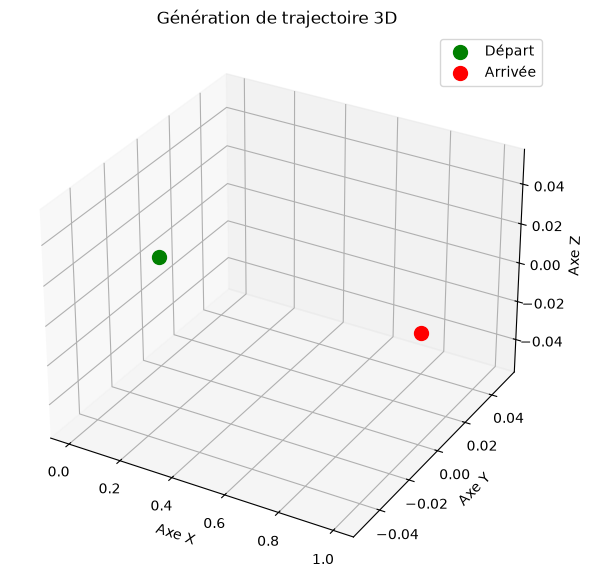

In [53]:
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

# Points de départ et d'arrivée
ax.scatter(depart[0][0], depart[1][0], int(depart[2][0]), color='green', s=100, label='Départ')
ax.scatter(arrivee[0][0], arrivee[1][0], int(arrivee[2][0]), color='red', s=100, label='Arrivée')


# Tracé de la trajectoire
#ax.plot(position['x'], position['y'], position['z'], label='Trajectoire 3D', color='b', lw=2)

ax.set_title("Génération de trajectoire 3D ")
ax.set_xlabel("Axe X")
ax.set_ylabel("Axe Y")
ax.set_zlabel("Axe Z")
ax.legend()
plt.show()